# Part 1: Data Loading, Cleaning, EDA, and Train/Test Split

In [22]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from src.config import FIGURES_DIR, RESULTS_DIR, RANDOM_STATE, TARGET
from src.data import load_column_names, load_spambase, clean_spambase, get_train_test

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

### Plot style

In [23]:
# Boilerplate styling
HAM, SPAM = "#2a78d6", "#eb6834"
NEUTRAL = "#8a8984"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
CLASS_COLORS = {0: HAM, 1: SPAM}
CLASS_NAMES = {0: "Non-spam", 1: "Spam"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

def save(fig, name):
    part1_dir = FIGURES_DIR / "part1"
    part1_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(part1_dir / name)

## 1. Load data

In [24]:
df_raw = load_spambase()
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (4601, 58)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,0.00,0.64,0.00,0.00,0.00,0.32,0.00,1.29,1.93,0.00,0.96,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,0.21,0.79,0.65,0.21,0.14,0.14,0.07,0.28,3.47,0.00,1.59,0.0,0.43,0.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,0.38,0.45,0.12,0.00,1.75,0.06,0.06,1.03,1.36,0.32,0.51,0.0,1.16,0.06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.06,0.0,0.0,0.12,0.0,0.06,0.06,0.0,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [25]:
print(df_raw.dtypes.value_counts())

float64    55
int64       3
Name: count, dtype: int64


## 2. Data quality checks

### 2.1 Missing values

In [26]:
n_missing = int(df_raw.isna().sum().sum())
print("Total missing values:", n_missing)

Total missing values: 0


### 2.2 Invalid values

In [27]:
features = df_raw.columns.drop(TARGET)
pct_cols = [c for c in features if c.startswith(("word_freq_", "char_freq_"))]
cap_cols = [c for c in features if c.startswith("capital_run_length_")]

print("Percentage features outside [0, 100]:", int(((df_raw[pct_cols] < 0) | (df_raw[pct_cols] > 100)).sum().sum()))
print("Capital-run features < 1:            ", int((df_raw[cap_cols] < 1).sum().sum()))
print("Target values:                        ", sorted(df_raw[TARGET].unique()))

Percentage features outside [0, 100]: 0
Capital-run features < 1:             0
Target values:                         [np.int64(0), np.int64(1)]


### 2.3 Duplicates

In [28]:
dup_mask = df_raw.duplicated(keep="first")
print(f"Duplicate rows: {dup_mask.sum()} ({dup_mask.mean():.1%} of the data)")
print("Duplicates by class:", df_raw[dup_mask][TARGET].map(CLASS_NAMES).value_counts().to_dict())

deduped = df_raw.drop_duplicates()
conflicts = deduped[deduped[features].duplicated(keep=False)]
print("Identical feature vectors with conflicting labels:", len(conflicts), "rows")

Duplicate rows: 391 (8.5% of the data)
Duplicates by class: {'Non-spam': 257, 'Spam': 134}
Identical feature vectors with conflicting labels: 6 rows


### 2.4 Outliers

In [29]:
df_raw[cap_cols].describe(percentiles=[.5, .9, .99]).round(1)

,capital_run_length_average,capital_run_length_longest,capital_run_length_total
count,4601.0,4601.0,4601.0
mean,5.2,52.2,283.3
std,31.7,194.9,606.3
min,1.0,1.0,1.0
50%,2.3,15.0,95.0
90%,6.1,99.0,725.0
99%,44.7,669.0,3027.0
max,1102.5,9989.0,15841.0


### 2.5 Class balance

In [30]:
counts = df_raw[TARGET].value_counts().sort_index()
pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(1)}).rename(index=CLASS_NAMES)

,count,percent
spam,,
Non-spam,2788,60.6
Spam,1813,39.4


### Data-quality decisions

| Check | Finding | Decision |
|---|---|---|
| Missing values | None (0 cells) | Nothing to impute. |
| Invalid values | None: all percentages in [0, 100], all run lengths ≥ 1, target is 0/1 | No rows removed. |
| Duplicate rows | 391 exact duplicate rows (8.5%) | Drop, keep first. With a random split, a duplicate could land in both train and test, so the model would be scored on e-mails it has already seen (train–test leakage). |
| Conflicting labels | 6 rows (3 pairs) share an identical feature vector but have different labels | Keep. There's no basis for deciding which label is right, and it's too few rows to matter. This is irreducible noise, and no model can classify both copies correctly. |
| Outliers | capital_run_length_* are extremely right-skewed (max total = 15,841 vs. median ≈ 95) | Keep. Long ALL-CAPS runs are real spam behaviour, not recording errors. Tree models are unaffected by scale, and Parts 2–3 handle scaling for distance- and gradient-based models. |
| Class imbalance | 60.6% non-spam / 39.4% spam | Moderate. No resampling, but the split is stratified, and accuracy alone is not enough: Parts 2–4 should report precision, recall, F1, and ROC-AUC. |
| Scaling | Features are on very different scales | Not done here. Scaling is learned from data, so it must be fit on training data only, inside each model's Pipeline. |

In [31]:
df = clean_spambase(df_raw)
print("Before cleaning:", df_raw.shape, " After cleaning:", df.shape)
counts_clean = df[TARGET].value_counts().sort_index()
print("Class counts after cleaning:", counts_clean.rename(index=CLASS_NAMES).to_dict(),
      f"(spam = {df[TARGET].mean():.1%})")

Before cleaning: (4601, 58)  After cleaning: (4210, 58)
Class counts after cleaning: {'Non-spam': 2531, 'Spam': 1679} (spam = 39.9%)


## 3. Data dictionary

In [32]:
groups = {
    "word_freq_*": ("48", "% of words in the e-mail equal to WORD: 100·count(WORD) / total words", "percent, [0, 100]"),
    "char_freq_*": ("6",  "% of characters equal to CHAR (; ( [ ! $ #): 100·count(CHAR) / total chars", "percent, [0, 100]"),
    "capital_run_length_average": ("1", "Average length of uninterrupted runs of capital letters", "characters, ≥ 1"),
    "capital_run_length_longest": ("1", "Length of the longest run of capital letters", "characters, ≥ 1 (integer)"),
    "capital_run_length_total":   ("1", "Total number of capital letters in the e-mail", "characters, ≥ 1 (integer)"),
    TARGET: ("1", "1 = spam (unsolicited commercial e-mail), 0 = non-spam", "binary {0, 1}"),
}
data_dict = pd.DataFrame(groups, index=["# columns", "meaning", "units / range"]).T
RESULTS_DIR = RESULTS_DIR / "part1"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
data_dict.to_csv(RESULTS_DIR / "data_dictionary.csv")
data_dict

,# columns,meaning,units / range
word_freq_*,48,% of words in the e-mail equal to WORD: 100·co...,"percent, [0, 100]"
char_freq_*,6,% of characters equal to CHAR (; ( [ ! $ #): 1...,"percent, [0, 100]"
capital_run_length_average,1,Average length of uninterrupted runs of capita...,"characters, ≥ 1"
capital_run_length_longest,1,Length of the longest run of capital letters,"characters, ≥ 1 (integer)"
capital_run_length_total,1,Total number of capital letters in the e-mail,"characters, ≥ 1 (integer)"
spam,1,"1 = spam (unsolicited commercial e-mail), 0 = ...","binary {0, 1}"


In [33]:
summary = df[features].describe().T
summary["% zero"] = (df[features] == 0).mean() * 100
summary = summary.round(3)
summary.to_csv(RESULTS_DIR / "feature_summary.csv")
summary

,count,mean,std,min,25%,50%,75%,max,% zero
word_freq_make,4210.0,0.104,0.300,0.0,0.000,0.000,0.000,4.540,76.675
word_freq_address,4210.0,0.113,0.454,0.0,0.000,0.000,0.000,14.280,80.736
word_freq_all,4210.0,0.291,0.516,0.0,0.000,0.000,0.440,5.100,57.625
word_freq_3d,4210.0,0.063,1.352,0.0,0.000,0.000,0.000,42.810,98.907
word_freq_our,4210.0,0.325,0.688,0.0,0.000,0.000,0.410,10.000,60.594
word_freq_over,4210.0,0.097,0.276,0.0,0.000,0.000,0.000,5.880,77.838
word_freq_remove,4210.0,0.117,0.397,0.0,0.000,0.000,0.000,7.270,81.900
word_freq_internet,4210.0,0.108,0.410,0.0,0.000,0.000,0.000,11.110,81.781
word_freq_order,4210.0,0.092,0.282,0.0,0.000,0.000,0.000,5.260,82.850
word_freq_mail,4210.0,0.248,0.657,0.0,0.000,0.000,0.190,18.180,70.808


## 4. Target distribution

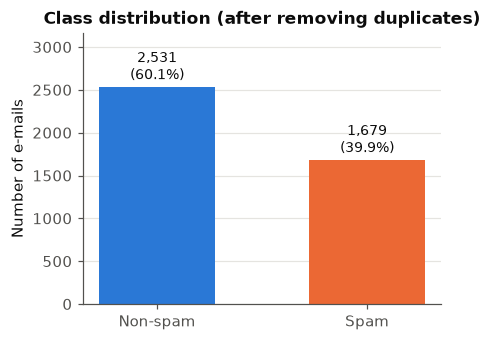

In [34]:
fig, ax = plt.subplots(figsize=(4.2, 3.2))
labels = [CLASS_NAMES[k] for k in counts_clean.index]
bars = ax.bar(labels, counts_clean.values, color=[CLASS_COLORS[k] for k in counts_clean.index], width=0.55)
for b, n in zip(bars, counts_clean.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 40, f"{n:,}\n({n / counts_clean.sum():.1%})",
            ha="center", va="bottom", color=INK, fontsize=9)
ax.set_ylabel("Number of e-mails")
ax.set_ylim(0, counts_clean.max() * 1.25)
ax.grid(axis="x", visible=False)
ax.set_title("Class distribution (after removing duplicates)")
save(fig, "fig1_target_distribution.png")
plt.show()

Fig. 1 interpretation: About 40% of the e-mails are spam. The classes are imbalanced but not severely. A model that always predicts "non-spam" already gets ~60% accuracy, so that is the baseline every model must beat, and it's why accuracy alone is a misleading metric here.

## 5. Feature distributions

Median % of e-mails where a feature is zero: 84.2%
Features that are zero in >90% of e-mails:   18 of 57


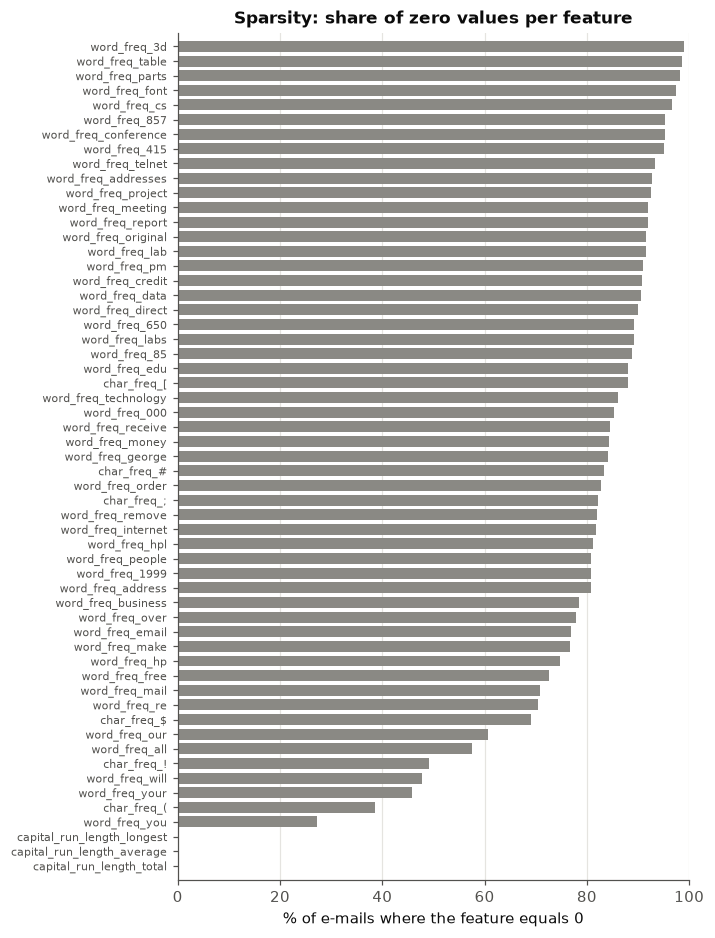

In [35]:
zero_pct = ((df[features] == 0).mean() * 100).sort_values()
print(f"Median % of e-mails where a feature is zero: {zero_pct.median():.1f}%")
print(f"Features that are zero in >90% of e-mails:   {(zero_pct > 90).sum()} of {len(features)}")

fig, ax = plt.subplots(figsize=(6, 10))
ax.barh(zero_pct.index, zero_pct.values, color=NEUTRAL, height=0.75)
ax.set_xlabel("% of e-mails where the feature equals 0")
ax.set_xlim(0, 100)
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="y", visible=False)
ax.margins(y=0.01)
ax.set_title("Sparsity: share of zero values per feature")
save(fig, "fig2_zero_fraction.png")
plt.show()

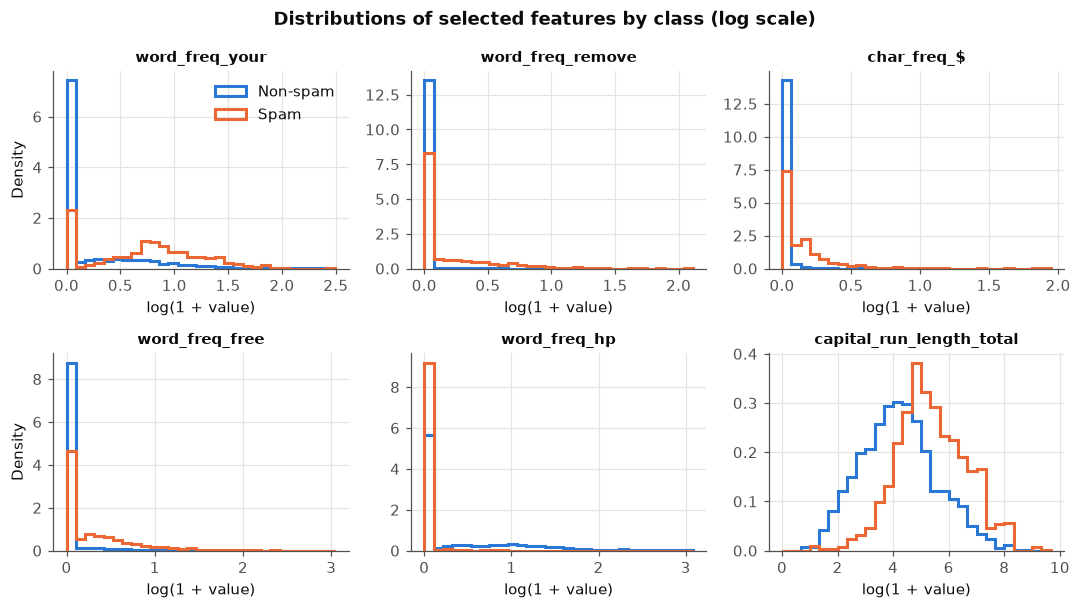

In [36]:
show = ["word_freq_your", "word_freq_remove", "char_freq_$", "word_freq_free", "word_freq_hp", "capital_run_length_total"]

fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
for ax, col in zip(axes.flat, show):
    vals = np.log1p(df[col])
    bins = np.linspace(0, vals.max(), 30)
    for k in (0, 1):
        ax.hist(vals[df[TARGET] == k], bins=bins, histtype="step", linewidth=2,
                color=CLASS_COLORS[k], label=CLASS_NAMES[k], density=True)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("log(1 + value)")
axes[0, 0].set_ylabel("Density")
axes[1, 0].set_ylabel("Density")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Distributions of selected features by class (log scale)", fontweight="bold")
fig.tight_layout()
save(fig, "fig3_feature_distributions.png")
plt.show()

Figs. 2–3 interpretation: The features are highly sparse and right-skewed. Most words appear in only a small fraction of e-mails, so most columns are zero for the large majority of rows (Fig. 2). Where a feature is nonzero, the values have a long right tail, which is why Fig. 3 uses log(1 + x). Two modeling consequences follow:
1. Scale-sensitive models (KNN, logistic regression) need standardization. Otherwise capital_run_length_total (up to ~15,000) dominates the percentage features (≤ 100).
2. Presence vs. absence is a strong signal by itself. Spam and non-spam differ more in *whether* a word appears than in its exact frequency. Tree-based models capture this naturally with a split near 0.

## 6. Feature–target relationships

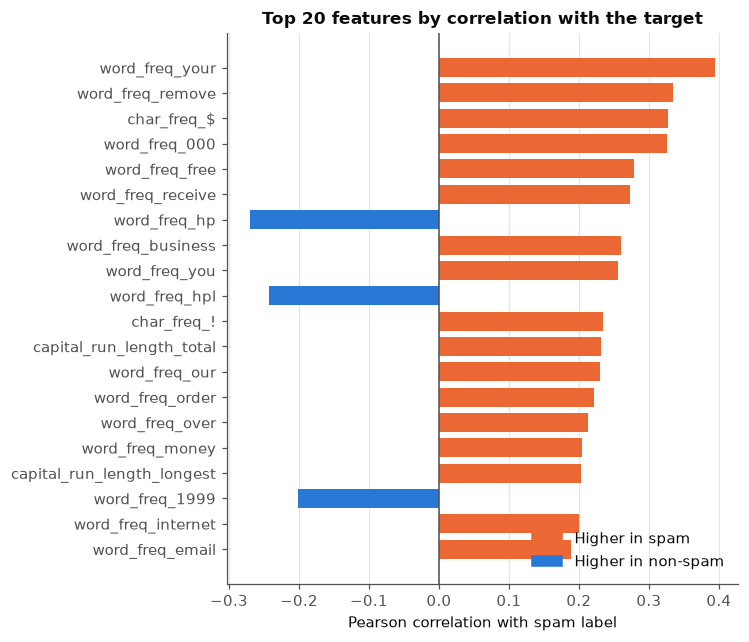

In [37]:
r_target = df[features].corrwith(df[TARGET]).sort_values(key=abs, ascending=False)
r_target.round(3).to_frame("corr_with_spam").to_csv(RESULTS_DIR / "feature_target_correlation.csv")

top = r_target.head(20)[::-1]
fig, ax = plt.subplots(figsize=(6, 6.5))
ax.barh(top.index, top.values, color=[SPAM if v > 0 else HAM for v in top.values], height=0.75)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_xlabel("Pearson correlation with spam label")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=SPAM, label="Higher in spam"), Patch(color=HAM, label="Higher in non-spam")],
          loc="lower right")
ax.set_title("Top 20 features by correlation with the target")
save(fig, "fig4_target_correlation.png")
plt.show()

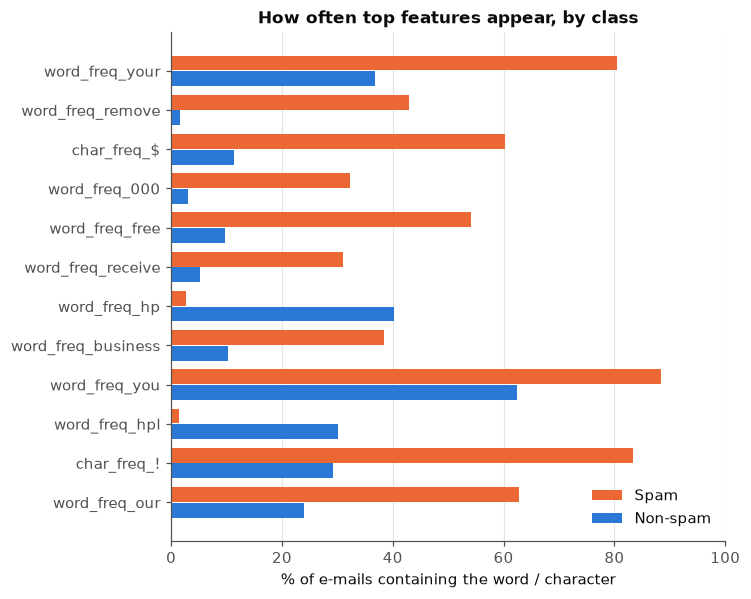

,Non-spam,Spam
word_freq_your,36.9,80.5
word_freq_remove,1.6,42.9
char_freq_$,11.3,60.2
word_freq_000,3.0,32.3
word_freq_free,9.8,54.1
word_freq_receive,5.2,31.0
word_freq_hp,40.2,2.7
word_freq_business,10.3,38.4
word_freq_you,62.4,88.4
word_freq_hpl,30.2,1.5


In [38]:
pct_feats = [c for c in r_target.index if c in pct_cols][:12]
present = (df[pct_feats] > 0).groupby(df[TARGET]).mean().T * 100
present.columns = [CLASS_NAMES[k] for k in present.columns]
present = present.loc[pct_feats[::-1]]

y = np.arange(len(present))
h = 0.38
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.barh(y + h / 2 + 0.01, present["Spam"], height=h, color=SPAM, label="Spam")
ax.barh(y - h / 2 - 0.01, present["Non-spam"], height=h, color=HAM, label="Non-spam")
ax.set_yticks(y, present.index)
ax.set_xlabel("% of e-mails containing the word / character")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("How often top features appear, by class")
save(fig, "fig5_presence_by_class.png")
plt.show()
present[::-1].round(1)

Figs. 4–5 interpretation:
- Spam indicators are commercial and urgency vocabulary: your, remove (as in "remove me from this list"), 000 (as in "$1,000,000"), free, receive, business, !, plus long runs of capital letters. Some are nearly exclusive to spam (Fig. 5): remove appeared in 42.9% of spam vs 1.6% of non-spam, 000 in 32.3% vs. 3.0% and "dollar_sign" in 60.2% vs. 11.3%.
- Non-spam indicators are hp, hpl, 1999, labs, george, 650, and lab. h` appears in 40.2% of non-spam but only 2.7% of spam. These are not general properties of legitimate e-mail. The dataset was donated by HP Labs (Hewlett-Packard, area code 650), and its non-spam messages came from the donor's own work and personal inbox (the donor is named George). A model will learn "mentions HP or George → not spam," which works on this data but won't generalize to other users' inboxes. This is a sampling-bias limitation to discuss in the report.

## 7. Correlation analysis

In [39]:
corr = df[features].corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("r").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
pairs = pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(10).reset_index(drop=True)
pairs.round(3).to_csv(RESULTS_DIR / "top_correlated_pairs.csv", index=False)
pairs.round(3)

,feature_a,feature_b,r
0,word_freq_857,word_freq_415,0.995
1,word_freq_857,word_freq_direct,0.824
2,word_freq_415,word_freq_direct,0.821
3,word_freq_telnet,word_freq_857,0.682
4,word_freq_telnet,word_freq_415,0.679
5,word_freq_857,word_freq_technology,0.672
6,word_freq_415,word_freq_technology,0.669
7,word_freq_telnet,word_freq_direct,0.641
8,word_freq_telnet,word_freq_technology,0.621
9,word_freq_technology,word_freq_direct,0.621


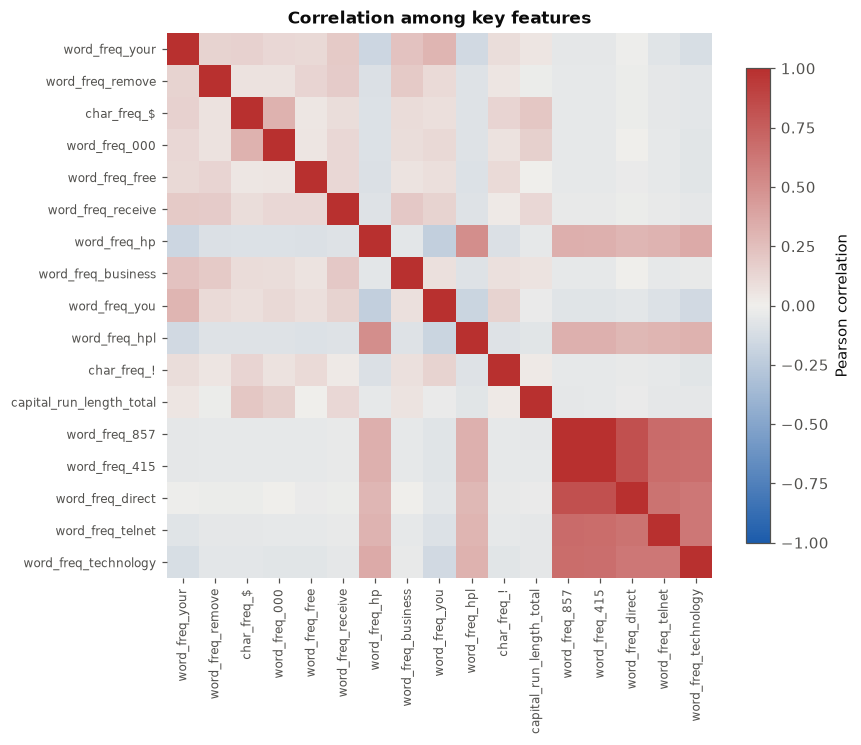

In [40]:
heat_cols = list(dict.fromkeys(list(r_target.head(12).index) +
                               ["word_freq_857", "word_freq_415", "word_freq_direct", "word_freq_telnet", "word_freq_technology"]))
cmap = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#f0efec", "#b8302f"])

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(df[heat_cols].corr(), cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(heat_cols)), heat_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(heat_cols)), heat_cols, fontsize=8)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Pearson correlation")
ax.set_title("Correlation among key features")
save(fig, "fig6_correlation_heatmap.png")
plt.show()

Fig. 6 interpretation:
- Most features are only weakly correlated with each other, so each word contributes mostly independent information.
- The exception is a near-duplicate cluster: 857 and 415 have r ≈ 0.99, and both correlate strongly with direct, telnet, and technology. The whole cluster also correlates with hp and hpl, so it is most likely a recurring HP Labs signature or contact block (phone numbers 415-xxx / 857-xxx) in the donor's non-spam mail, not a general spam pattern. This multicollinearity matters for logistic regression: coefficients for the pair become unstable and shouldn't be read individually. Trees and random forests are largely unaffected.
- The spam indicators correlate positively with each other (your, you, free, 000, $), consistent with a shared "marketing e-mail" style.
- No feature is a near-perfect proxy for the label (max |r| with target ≈ 0.39), so there's no obvious target leakage.

## 8. Train/test split

In [41]:
X_train, X_test, y_train, y_test = get_train_test()

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "spam": [int(y_train.sum()), int(y_test.sum())],
    "non-spam": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "% spam": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
}, index=["train", "test"])
split_summary.to_csv(RESULTS_DIR / "split_summary.csv")
print("Features:", X_train.shape[1])
split_summary

Features: 57


,rows,spam,non-spam,% spam
train,3368,1343,2025,39.9
test,842,336,506,39.9


In [42]:
shared_rows = pd.merge(X_train, X_test, how="inner").shape[0]
print("Feature rows appearing in both train and test:", shared_rows)
print("Overlapping indices:", len(set(X_train.index) & set(X_test.index)))

Feature rows appearing in both train and test: 0
Overlapping indices: 0


## 9. Summary of findings

Dataset: UCI Machine Learning Repository, *Spambase* (Hopkins, Reeber, Forman, Suermondt; Hewlett-Packard Labs, 1999). https://archive.ics.uci.edu/dataset/94/spambase, accessed _[date]_. License: CC BY 4.0. 4,601 e-mails, 57 continuous features, binary label.

Data quality: No missing or invalid values. 391 exact duplicate rows (8.5%) were removed to prevent train–test leakage, leaving 4,210 e-mails (39.9% spam). Three pairs of identical feature vectors carry conflicting labels; these are irreducible noise. Extreme capital-run values were kept because they reflect real spam behaviour.

Key EDA patterns.
1. Moderate imbalance (60/40). The majority-class baseline is ~60% accuracy, and precision/recall/F1/AUC are needed alongside accuracy.
2. Sparse, heavy-tailed features. Most features are zero for most e-mails and are on very different scales, so scaling is needed for KNN and logistic regression (fit on training data only).
3. Clear spam vocabulary. The strongest spam indicators are your, remove, $, 000, free, receive, !, and long ALL-CAPS runs.
4. Collection bias. The strongest non-spam indicators (hp, hpl, george, 650) are specific to the donor's workplace. Models will partly learn "this is an HP inbox," which limits generalization to other users.
5. Redundancy. 857 and 415 are almost perfectly correlated (r ≈ 0.99), which affects interpretation of linear-model coefficients.

Limitations to carry into the report. Single-organization sample, data from 1999 (modern spam differs: images, links, obfuscation), labels from one person's judgment, and a bag-of-words representation that loses word order and context.